# 01-1　牛頓的太陽系：軌道、克卜勒定律與水星之謎

**這一課什麼常數都不打開**：$c = \infty$、$\hbar = 0$，這就是牛頓的世界，也是之後每個單元比較的基準。

這一課做四個實驗：

1. 比較三種數值積分方法，學會分辨**數值誤差**和**真正的物理**
2. 用模擬驗證**克卜勒第三定律**，再和真實的行星週期比對
3. 只有太陽和水星時，水星的近日點**完全不會轉動**
4. 加入其他行星，牛頓力學能解釋水星進動的大部分，**但還差 43 角秒**，這要留到 04 單元由廣義相對論解決

## 理論

萬有引力定律：太陽（質量 $M$）對行星的加速度

$$\ddot{\vec r} = -\frac{GM}{r^3}\,\vec r$$

**單位**：長度用天文單位 AU（地日平均距離），時間用年。在這套單位裡地球繞一圈剛好 1 年，
由克卜勒第三定律可得 $GM_\odot = 4\pi^2$，數字乾淨很多。

**這條式子裡藏著兩個牛頓的假設**：

- 右邊用的是行星「**此刻**」的位置：太陽一動，行星**瞬間**就感覺到。引力傳播速度是無限大，也就是 $c = \infty$。
- $t$ 是全宇宙共用的**絕對時間**，所有人的時鐘走得一樣快。

這兩點在 03、04 單元會被相對論拆掉。

**近日點方向**：軌道最靠近太陽的方向，可以用 **Runge–Lenz 向量**精確算出來：

$$\vec A = \vec v \times \vec L - GM\,\hat r$$

在純粹的平方反比力之下，$\vec A$ 是守恆量，它的方向永遠不變，也就是說橢圓軌道不會轉。
任何讓 $\vec A$ 轉動的東西，都代表力偏離了 $1/r^2$，或者有其他天體在拉。

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

GM = 4 * np.pi**2            # 太陽，單位 AU³/年²
ARCSEC = 180 / np.pi * 3600  # 弧度 → 角秒

In [2]:
def kepler_acc(r, t):
    return -GM * r / np.hypot(*r) ** 3


def start_at_perihelion(a, e):
    # 從近日點出發：位置在 +x 軸，速度沿 +y（活力公式）
    r = a * (1 - e)
    v = np.sqrt(GM * (1 + e) / (a * (1 - e)))
    return np.array([r, 0.0]), np.array([0.0, v])


def energy(r, v):
    return 0.5 * v @ v - GM / np.hypot(*r)


def perihelion_angle(r, v):
    # Runge–Lenz 向量的方向
    L = r[0] * v[1] - r[1] * v[0]
    rn = np.hypot(*r)
    A = np.array([v[1] * L - GM * r[0] / rn, -v[0] * L - GM * r[1] / rn])
    return np.arctan2(A[1], A[0])


# ---- 三種積分器：每一步把 (r, v, t) 推進 dt ----
def step_euler(r, v, t, dt, acc):
    return r + dt * v, v + dt * acc(r, t), t + dt


def step_verlet(r, v, t, dt, acc):
    v = v + 0.5 * dt * acc(r, t)
    r = r + dt * v
    v = v + 0.5 * dt * acc(r, t + dt)
    return r, v, t + dt


_w1 = 1 / (2 - 2 ** (1 / 3))
_w0 = -(2 ** (1 / 3)) * _w1
_YC = [_w1 / 2, (_w0 + _w1) / 2, (_w0 + _w1) / 2, _w1 / 2]
_YD = [_w1, _w0, _w1]


def step_yoshida4(r, v, t, dt, acc):
    # 四階辛積分器：三次 Verlet 子步，權重設計成把誤差消到 dt⁴
    for c, d in zip(_YC[:3], _YD):
        r = r + c * dt * v
        t = t + c * dt
        v = v + d * dt * acc(r, t)
    return r + _YC[3] * dt * v, v, t + _YC[3] * dt


def integrate(r, v, dt, n, acc, step, every=1):
    # 回傳每 every 步記錄一次的 t、r、v
    t = 0.0
    ts, rs, vs = [t], [r], [v]
    for i in range(1, n + 1):
        r, v, t = step(r, v, t, dt, acc)
        if i % every == 0:
            ts.append(t)
            rs.append(r)
            vs.append(v)
    return np.array(ts), np.array(rs), np.array(vs)

## 實驗 1：三種積分器，誰在說謊？

電腦沒辦法算連續時間，只能一小步一小步 $dt$ 往前推。推的方法不同，誤差的性質差很多。
用水星軌道（偏心率 0.2056），每圈只走 200 步，跑 10 圈：

| 方法 | 階數 | 特性 |
|---|---|---|
| Euler | 1 | 最直覺：用現在的速度和加速度往前走 |
| Verlet（蛙跳） | 2 | **辛積分器**：能量不會一路漂走 |
| Yoshida | 4 | 辛積分器，而且誤差和 $dt^4$ 成正比 |

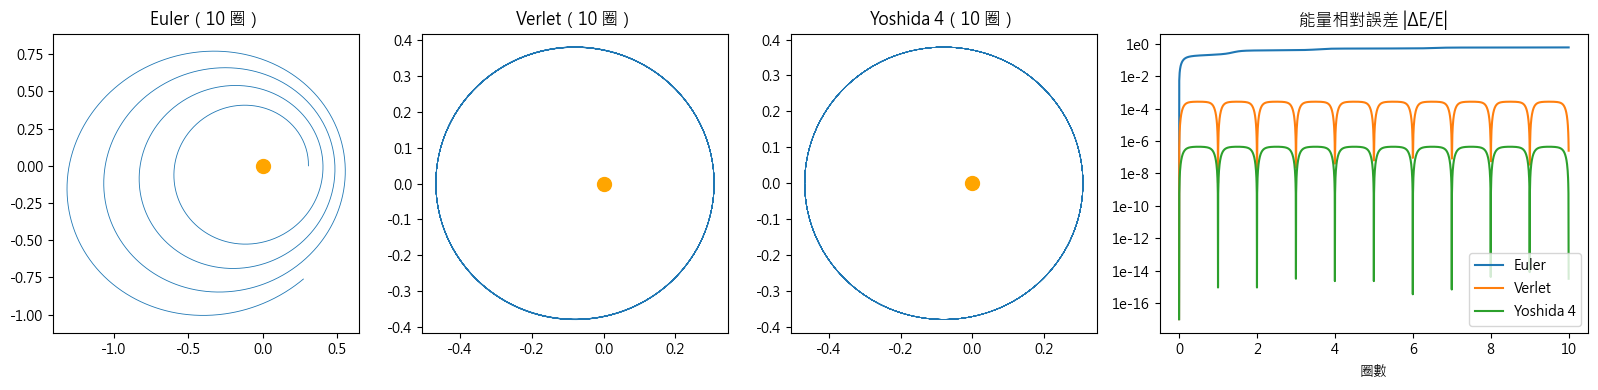

In [3]:
aM, eM = 0.387098, 0.205630                 # 水星的半長軸 (AU) 與偏心率
T_M = 2 * np.pi * np.sqrt(aM**3 / GM)       # 水星週期（年）
r0, v0 = start_at_perihelion(aM, eM)
E0 = energy(r0, v0)

methods = {"Euler": step_euler, "Verlet": step_verlet, "Yoshida 4": step_yoshida4}
spo = 200                                    # steps per orbit
fig, axes = plt.subplots(1, 4, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 1, 1, 1.4]})
for ax, (name, step) in zip(axes[:3], methods.items()):
    ts, rs, vs = integrate(r0, v0, T_M / spo, 10 * spo, kepler_acc, step)
    ax.plot(rs[:, 0], rs[:, 1], lw=0.6)
    ax.plot(0, 0, "o", color="orange", ms=10)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(f"{name}（10 圈）")
    dE = np.array([energy(r, v) for r, v in zip(rs, vs)]) / E0 - 1
    axes[3].plot(ts / T_M, np.abs(dE) + 1e-17, label=name)
axes[3].set_yscale("log")
axes[3].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"1e{np.log10(y):.0f}"))  # 避開數學字型缺負號
axes[3].set_xlabel("圈數")
axes[3].set_title("能量相對誤差 |ΔE/E|")
axes[3].legend()
plt.tight_layout()
plt.show()

**觀察**：

- **Euler**：能量一路增加，行星**螺旋往外飛走**。這不是物理，是方法的錯。
- **Verlet**：能量誤差只在小範圍內上下擺動，**不會累積**，這是辛積分器的特性。軌道圖看起來和 Yoshida 一樣好。
- **Yoshida**：能量誤差又小了大約 100 倍。

但「圖看起來沒問題」不代表沒問題。Verlet 的軌道其實**每圈都偷偷轉一點**，10 圈只轉了大約 1°，肉眼看不出來，
可是累積 100 年（415 圈），假進動就超過 15 萬角秒。實驗 3 會把它量出來。

這個實驗的教訓很重要：**數值誤差可以假扮成物理效應。** Verlet 畫出來的進動是假的。
要測水星每世紀 43 角秒的真進動，就必須先確定數值方法本身的假進動遠小於 43。

## 實驗 2：克卜勒第三定律，對照真實行星

克卜勒第三定律：$T^2 \propto a^3$。在 AU／年的單位裡就是 $T = a^{3/2}$ 年。

做法：模擬每顆行星繞一圈，量出週期，再和天文觀測到的真實週期比較。

In [4]:
# 名稱, 半長軸 a (AU), 偏心率 e, 質量 (太陽 = 1), 觀測恆星週期 (天)
PLANETS = [
    ("水星", 0.387098, 0.2056, 1.6601e-7, 87.969),
    ("金星", 0.723332, 0.0068, 2.4478e-6, 224.701),
    ("地球", 1.000000, 0.0167, 3.0404e-6, 365.256),  # 含月球
    ("火星", 1.523662, 0.0934, 3.2272e-7, 686.980),
    ("木星", 5.203363, 0.0489, 9.5479e-4, 4332.59),
    ("土星", 9.537070, 0.0565, 2.8589e-4, 10759.22),
    ("天王星", 19.19126, 0.0457, 4.3662e-5, 30688.5),
    ("海王星", 30.06896, 0.0113, 5.1514e-5, 60182.0),
]


def measured_period(a, e, spo=2000):
    # 模擬，找出位置角第一次轉滿 2π 的時刻（線性內插）
    T_guess = a**1.5
    ts, rs, _ = integrate(*start_at_perihelion(a, e), T_guess / spo, int(1.05 * spo), kepler_acc, step_yoshida4)
    ang = np.unwrap(np.arctan2(rs[:, 1], rs[:, 0]))
    i = np.argmax(ang >= 2 * np.pi)
    return ts[i - 1] + (2 * np.pi - ang[i - 1]) / (ang[i] - ang[i - 1]) * (ts[i] - ts[i - 1])


print(f"{'行星':<6}{'a (AU)':>10}{'模擬 T (天)':>14}{'觀測 T (天)':>14}{'差異':>10}{'T²/a³':>10}")
for name, a, e, m, T_obs in PLANETS:
    T_sim = measured_period(a, e) * 365.25
    print(f"{name:<6}{a:>10.4f}{T_sim:>14.3f}{T_obs:>14.3f}{T_sim / T_obs - 1:>+10.2%}{(T_sim / 365.25) ** 2 / a**3:>10.6f}")

行星        a (AU)      模擬 T (天)      觀測 T (天)        差異     T²/a³
水星        0.3871        87.967        87.969    -0.00%  1.000000
金星        0.7233       224.697       224.701    -0.00%  1.000000
地球        1.0000       365.250       365.256    -0.00%  1.000000
火星        1.5237       686.947       686.980    -0.00%  1.000000
木星        5.2034      4335.273      4332.590    +0.06%  1.000000
土星        9.5371     10757.533     10759.220    -0.02%  1.000000
天王星      19.1913     30707.571     30688.500    +0.06%  1.000000
海王星      30.0690     60223.756     60182.000    +0.07%  1.000000


**觀察**：

- 模擬的 $T^2/a^3$ 全部等於 1，克卜勒第三定律在牛頓重力下成立。
- 和**真實觀測**比較，八顆行星差異都在 0.1% 以內，從 88 天的水星到 165 年的海王星都一樣。
- 剩下那一點點差異有兩個來源：
  - **木星**的 +0.06%，主要因為我們把行星質量當成 0。真實週期是 $T = 2\pi\sqrt{a^3/G(M+m)}$，木星質量是太陽的千分之一，會讓週期縮短約 0.05%。
  - **天王星、海王星**的質量小得多，它們的差異主要來自其他行星（尤其是木星、土星）的拉扯，以及表中「半長軸」本身是長期平均值。

牛頓力學在太陽系尺度準到這種程度，這也是為什麼後面那 43 角秒的偏差，會成為一個嚴重的問題。

## 實驗 3：只有太陽和水星，近日點會轉嗎？

用 Runge–Lenz 向量追蹤近日點方向，模擬 **100 年**（約 415 圈）。
同時改變步長，確認我們量到的是物理而不是數值誤差：

In [5]:
def precession_rate(acc, years=100, spo=1000, step=step_yoshida4):
    # 模擬水星，回傳近日點進動率（角秒／世紀）
    dt = T_M / spo
    ts, rs, vs = integrate(*start_at_perihelion(aM, eM), dt, int(years / dt), acc, step, every=spo // 20)
    angles = np.unwrap([perihelion_angle(r, v) for r, v in zip(rs, vs)])
    return np.polyfit(ts, angles, 1)[0] * 100 * ARCSEC


print(f"{'每圈步數':>8}{'Verlet':>16}{'Yoshida 4':>16}   （角秒／世紀）")
for spo in (250, 500, 1000):
    pv = precession_rate(kepler_acc, spo=spo, step=step_verlet)
    py = precession_rate(kepler_acc, spo=spo)
    print(f"{spo:>8}{pv:>16.2f}{py:>16.3f}")

    每圈步數          Verlet       Yoshida 4   （角秒／世紀）


     250       -97658.92        -291.005


     500       -24433.09         -18.227


    1000        -6109.42          -1.140


**觀察**：

- **純牛頓、只有太陽時，真正的進動是 0**，因為平方反比力的 Runge–Lenz 向量守恆。
- 表格裡不是 0 的數字全是**數值誤差**：
  - Verlet 每次步長減半，誤差縮小約 4 倍（$\propto dt^2$）。每圈 1000 步時仍有約 −6000″/世紀，比要找的 43″ 大 100 多倍，**完全不能用**。
  - Yoshida 每次步長減半，誤差縮小約 16 倍（$\propto dt^4$）。每圈 1000 步時只剩約 1″，**夠用了**。

接下來都用 **Yoshida、每圈 1000 步**。

## 實驗 4：加入其他行星，水星還差多少？

真實的水星近日點**有在轉**，每世紀約 **574 角秒**（相對於遙遠恆星）。
19 世紀的天文學家認為這是其他行星的引力拉扯造成的，所以來算算看。

**模型**：其他七顆行星沿著圓形軌道公轉（和水星在同一平面），每顆都對水星施力。
因為我們把太陽固定在原點，而太陽本身也被行星拉著動，所以還要加上一項「**間接項**」來修正這個非慣性座標系。

**對照用的解析理論**：Laplace–Lagrange 長期攝動理論。對一顆在外側、圓軌道、質量 $m'$、半長軸 $a'$ 的行星，它造成的進動率是

$$\dot\varpi = \frac{n}{4}\,\frac{m'}{M_\odot}\,\alpha^2\,b^{(1)}_{3/2}(\alpha),\qquad \alpha = a/a'$$

其中 $n$ 是水星的平均角速度，$b^{(1)}_{3/2}$ 是 Laplace 係數（一個積分）。

（這格大約要跑 3–6 分鐘，看電腦當下的負載：8 次各 100 年的模擬。）

In [6]:
def make_perturbed_acc(perturbers):
    # perturbers: [(a, 質量)...]，各自沿圓軌道公轉，起始相位錯開
    pa = np.array([p[0] for p in perturbers])
    pm = np.array([p[1] for p in perturbers])
    pw = np.sqrt(GM / pa**3)
    ph = np.linspace(0, 2 * np.pi, len(pa), endpoint=False)

    def acc(r, t):
        P = np.stack([pa * np.cos(pw * t + ph), pa * np.sin(pw * t + ph)], axis=1)
        d = P - r
        direct = d / np.hypot(d[:, 0], d[:, 1])[:, None] ** 3     # 行星直接拉水星
        indirect = P / pa[:, None] ** 3                             # 行星拉太陽（座標修正）
        return kepler_acc(r, t) + GM * np.sum(pm[:, None] * (direct - indirect), axis=0)

    return acc


def laplace_b32(alpha):
    f = lambda psi: np.cos(psi) / (1 - 2 * alpha * np.cos(psi) + alpha**2) ** 1.5
    return quad(f, 0, 2 * np.pi)[0] / np.pi


def secular_rate(a_p, m_p):
    n = 2 * np.pi / T_M
    alpha = aM / a_p
    return n / 4 * m_p * alpha**2 * laplace_b32(alpha) * 100 * ARCSEC


# 精確文獻值（用真實的橢圓、傾斜軌道計算）
LITERATURE = {"金星": 277.856, "地球": 90.038, "火星": 2.536, "木星": 153.584, "土星": 7.302, "天王星": 0.141, "海王星": 0.042}

t0 = time.time()
baseline = precession_rate(kepler_acc)      # 同樣設定下的數值誤差，要扣掉
rows = []
for name, a, e, m, _ in PLANETS[1:]:
    sim = precession_rate(make_perturbed_acc([(a, m)])) - baseline
    rows.append((name, sim, secular_rate(a, m), LITERATURE[name]))
total_sim = precession_rate(make_perturbed_acc([(a, m) for _, a, _, m, _ in PLANETS[1:]])) - baseline

print(f"{'行星':<6}{'模擬':>10}{'解析理論':>10}{'精確文獻值':>12}   （角秒／世紀）")
for name, sim, sec, lit in rows:
    print(f"{name:<6}{sim:>10.1f}{sec:>10.1f}{lit:>12.1f}")
print("-" * 44)
print(f"{'合計':<6}{total_sim:>10.1f}{sum(r[2] for r in rows):>10.1f}{sum(LITERATURE.values()):>12.1f}")
print(f"\n（扣除的數值基線：{baseline:.2f}″／世紀；耗時 {time.time() - t0:.0f} 秒）")

行星            模擬      解析理論       精確文獻值   （角秒／世紀）
金星         293.1     286.3       277.9
地球          96.0      96.6        90.0
火星           2.4       2.4         2.5
木星         156.3     160.3       153.6
土星           7.4       7.7         7.3
天王星          0.1       0.1         0.1
海王星          0.0       0.0         0.0
--------------------------------------------
合計         555.6     553.5       531.5

（扣除的數值基線：-1.14″／世紀；耗時 160 秒）


**觀察**：

- **模擬和解析理論互相吻合**，兩種完全不同的方法得到一樣的答案。
- 金星最大，因為它最近；木星第二，因為它最重；遠方的天王星、海王星幾乎沒有影響。
- 我們的數字比文獻值高大約 4–5%。原因是模型簡化了：真實的行星軌道是橢圓，而且各自傾斜，水星軌道本身就傾斜 7°。
  天文學家用完整的真實軌道計算，七顆行星合計 531.5″，再加上太陽扁率等微小項，總共約 **531.6″／世紀**。

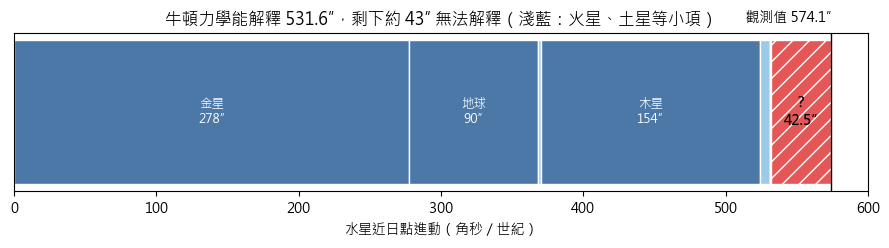

無法解釋的差距：42.5″／世紀


In [7]:
observed = 574.1          # 觀測到的水星近日點進動（相對遙遠恆星）
newton = 531.6            # 牛頓力學 + 所有行星攝動（精確計算）
gap = observed - newton

fig, ax = plt.subplots(figsize=(9, 2.6))
left = 0
for name, val in LITERATURE.items():
    ax.barh(0, val, left=left, color="#4c78a8" if val > 20 else "#9ecae9", edgecolor="white")
    if val > 20:   # 小項目（火星、土星…）太窄，不標字
        ax.text(left + val / 2, 0, f"{name}\n{val:.0f}″", ha="center", va="center", color="white", fontsize=9)
    left += val
ax.barh(0, gap, left=newton, color="#e45756", hatch="//", edgecolor="white")
ax.text(newton + gap / 2, 0, f"？\n{gap:.1f}″", ha="center", va="center", color="black", fontsize=10, weight="bold")
ax.axvline(observed, color="k", lw=1)
ax.text(observed, 0.48, f" 觀測值 {observed}″", va="bottom", ha="right")
ax.set_xlim(0, 600)
ax.set_yticks([])
ax.set_xlabel("水星近日點進動（角秒／世紀）")
ax.set_title("牛頓力學能解釋 531.6″，剩下約 43″ 無法解釋（淺藍：火星、土星等小項）")
plt.tight_layout()
plt.show()
print(f"無法解釋的差距：{gap:.1f}″／世紀")

## 歷史：差點找到一顆不存在的行星

- **1846 年**，天文學家 Le Verrier 注意到天王星的軌道怪怪的，推論外面還有一顆行星。依他算出的位置一看，**真的找到了海王星**。這是牛頓力學最輝煌的勝利。
- **1859 年**，同一位 Le Verrier 發現水星進動也多出一截（後來量得更準，就是 43″），於是如法炮製，預言水星軌道內側還有一顆行星，取名「**祝融星**（Vulcan）」。
- 接下來幾十年，很多人宣稱看到了祝融星，但**它從來不存在**。
- **1915 年**，愛因斯坦用廣義相對論算出水星進動多出 **43″／世紀**，不需要任何新行星。他後來說，算出這個數字時興奮得心悸了好幾天。

同一種「多出來的偏差」，第一次答案是**多一顆行星**（牛頓力學沒錯），第二次答案是**牛頓力學本身要換掉**。
到了 04 單元，我們會用廣義相對論把這 43″ 算出來。

## 總結

| 實驗 | 結果 | 學到什麼 |
|---|---|---|
| 積分器比較 | Euler 讓行星飛走，Verlet 製造假進動 | 數值誤差會假扮成物理，一定要驗證收斂 |
| 克卜勒第三定律 | 8 顆行星和真實週期差異都在 0.1% 以內 | 牛頓力學在太陽系非常準 |
| 只有太陽 | 進動 = 0（Runge–Lenz 守恆） | 平方反比力的軌道是封閉的 |
| 加入其他行星 | 解釋了 531.6″，還差 43″ | 牛頓力學的第一道裂縫 |

## 練習

1. 實驗 1 改成每圈 50 步，三種方法各會變成什麼樣子？
2. 把木星的質量放大 10 倍，水星的進動會變成多少？是不是剛好 10 倍？為什麼？
3. 把 `kepler_acc` 的 $1/r^2$ 改成 $1/r^{2.01}$，水星的進動是多少？要偏離多少才能剛好解釋 43″？（這是 19 世紀真的有人提過的想法。）